In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройки для красивых графиков
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

# Загружаем наши очищенные данные
df = pd.read_parquet('../data/processed/data_raw.parquet')
print(f"Размер данных: {df.shape}")
print(f"Колонки: {df.columns.tolist()}")
df.head()

Размер данных: (36293, 13)
Колонки: ['report_date', 'scenario', 'frequency', 'nomenclature_ru', 'prod_version', 'port_name_ru', 'country', 'location', 'basis', 'currency', 'measure_unit', 'k', 'выборка']


,report_date,scenario,frequency,nomenclature_ru,prod_version,port_name_ru,country,location,basis,currency,measure_unit,k,выборка
0,2021-01-01,факт,еженедельно,Нефть марки Brent,Ice Brent month 1 weekly avg,(н/д),Великобритания и Норвегия,North sea,FOB,USD,bl,1.000000,обучающая
1,2021-01-08,факт,еженедельно,Нефть марки Brent,Ice Brent month 1 weekly avg,(н/д),Великобритания и Норвегия,North sea,FOB,USD,bl,1.032378,обучающая
2,2021-01-15,факт,еженедельно,Нефть марки Brent,Ice Brent month 1 weekly avg,(н/д),Великобритания и Норвегия,North sea,FOB,USD,bl,1.096353,обучающая
3,2021-01-22,факт,еженедельно,Нефть марки Brent,Ice Brent month 1 weekly avg,(н/д),Великобритания и Норвегия,North sea,FOB,USD,bl,1.083090,обучающая
4,2021-01-29,факт,еженедельно,Нефть марки Brent,Ice Brent month 1 weekly avg,(н/д),Великобритания и Норвегия,North sea,FOB,USD,bl,1.085040,обучающая


In [2]:
# Смотрим уникальные значения в ключевых колонках
print("Уникальные группы продуктов (nomenclature_ru):")
print(df['nomenclature_ru'].value_counts().head(20))

print("\nУникальные ряды (prod_version):")
print(df['prod_version'].value_counts().head(20))

print("\nПериодичность (frequency):")
print(df['frequency'].value_counts())

Уникальные группы продуктов (nomenclature_ru):
nomenclature_ru
ПВХ-С марка К-67                                    11334
Нафта                                                7826
Этилен                                               7249
S-PVC                                                2848
ПВХ-С марка К-57                                     2486
Нефть марки Brent                                    1693
ПВХ-С марка К-60                                      880
ПВХ SG-5 (Китай)                                      666
Нафта 65 (ARGUS)                                      288
ПВХ SG-3 (Китай)                                      228
PVC pipe HC                                           187
s-PVC pipe                                            169
PVC pipe                                              126
ПВХ SG-5 (С.В. Азия)                                  114
ПВХ К-67 (США)                                        114
PVC pipe ex-works China range month                    43
PVC pipe 

In [5]:
# Выведи все уникальные prod_version, чтобы найти нужный
for name in df['prod_version'].unique():
    if 'SG' in str(name) or 'PVC' in str(name) or 'ПВХ' in str(name):
        print(name)

PVC pipe cfr China range month
PVC pipe ex-works China range month
PVC pipe HC fas Houston bagged USD/t range month
PVC pipe HC fas Houston bagged USD/t
PVC pipe HC fas Houston bagged USD/t monthly avg
S-PVC k70 cfr Turkey (EUROPE origin)
S-PVC k70 cfr Turkey (EUROPE origin) monthly avg
S-PVC pipe cfr Bangladesh
S-PVC pipe cfr Bangladesh monthly avg
S-PVC pipe cfr Brazil (US origin)
S-PVC pipe cfr Brazil (US origin) monthly avg
S-PVC pipe cfr China USD/t
S-PVC pipe cfr China USD/t monthly avg
S-PVC pipe cfr Egypt (EUROPE origin)
S-PVC pipe cfr Egypt (EUROPE origin) monthly avg
S-PVC pipe cfr GCC
S-PVC pipe cfr GCC monthly avg
S-PVC pipe cfr India
S-PVC pipe cfr India monthly avg
S-PVC pipe cfr Pakistan
S-PVC pipe cfr Pakistan monthly avg
S-PVC pipe cfr SE Asia
S-PVC pipe cfr SE Asia monthly avg
S-PVC pipe cfr Turkey (EUROPE origin)
S-PVC pipe cfr Turkey (EUROPE origin) monthly avg
S-PVC pipe cfr Turkey (US origin)
S-PVC pipe cfr Turkey (US origin) monthly avg
S-PVC pipe cfr West Coast 

In [7]:
# === ШАГ 1: Проверяем данные (без повторного преобразования даты) ===

# 1.1. Проверяем тип колонки report_date
print(f"Тип колонки report_date: {df['report_date'].dtype}")

# Если тип уже datetime64 — ничего не делаем.
# Если вдруг он числовой (int/float) — преобразуем.
if not pd.api.types.is_datetime64_any_dtype(df['report_date']):
    print("Преобразуем report_date из числового формата...")
    df['report_date'] = pd.to_datetime(df['report_date'], unit='D', origin='1899-12-30')
else:
    print("report_date уже в формате datetime. Преобразование не требуется.")

# 1.2. Фильтруем целевой ряд (ПВХ SG-5 Китай)
target_mask = df['prod_version'].str.contains('SG-5|SG-3', case=False, na=False) & \
              df['country'].str.contains('Китай', case=False, na=False)
df_target = df[target_mask].copy().sort_values('report_date')

# 1.3. Смотрим, сколько уникальных рядов попало в фильтр
print("\nУникальные названия целевого ряда:")
print(df_target['prod_version'].value_counts())
print(f"\nПериод: {df_target['report_date'].min()} — {df_target['report_date'].max()}")
print(f"Всего строк: {len(df_target)}")

Тип колонки report_date: datetime64[us]
report_date уже в формате datetime. Преобразование не требуется.

Уникальные названия целевого ряда:
Series([], Name: count, dtype: int64)

Период: NaT — NaT
Всего строк: 0


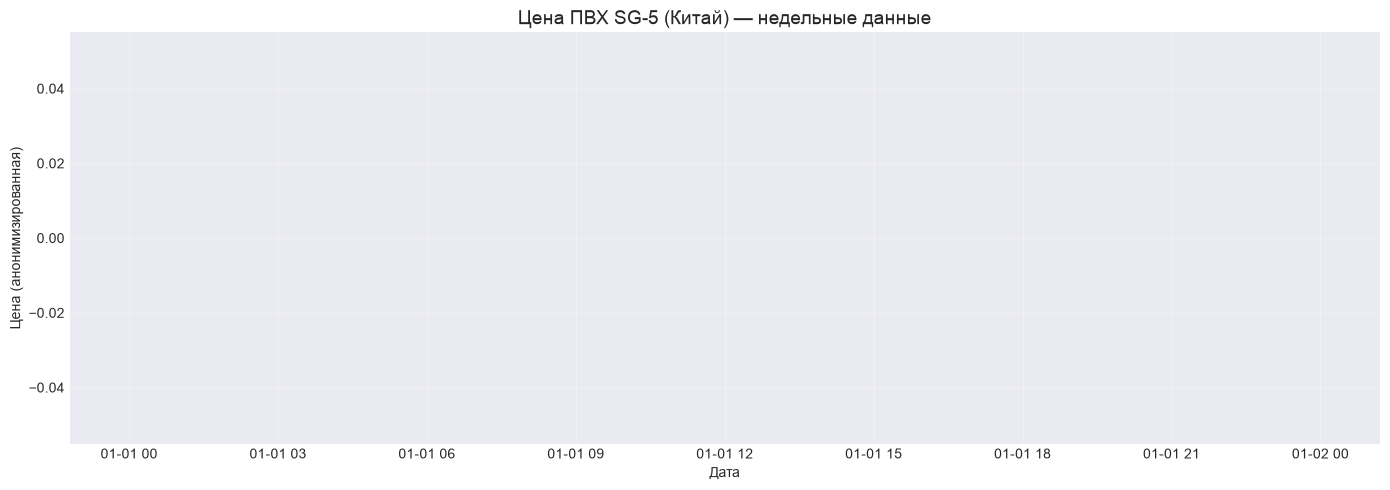

[!] Мало общих точек для Brent: 0
[!] Мало общих точек для Нафта: 0
[!] Для Этилен данных нет


In [10]:
# === ШАГ 2: Визуализация и корреляция ===
import matplotlib.pyplot as plt

# 2.1. Агрегируем по неделям (на случай, если в фильтр попали несколько рядов)
target_weekly = df_target.groupby(pd.Grouper(key='report_date', freq='W'))['k'].mean().reset_index()
target_weekly.columns = ['date', 'target_price']

# 2.2. Рисуем график
plt.figure(figsize=(14, 5))
plt.plot(target_weekly['date'], target_weekly['target_price'], linewidth=1.5, color='blue')
plt.title('Цена ПВХ SG-5 (Китай) — недельные данные', fontsize=14)
plt.xlabel('Дата')
plt.ylabel('Цена (анонимизированная)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2.3. Ищем драйверы и считаем корреляцию
drivers = ['Brent', 'Нафта', 'Этилен']
df_drivers = df[df['prod_version'].str.contains('|'.join(drivers), case=False, na=False)].copy()

for driver in drivers:
    mask = df_drivers['prod_version'].str.contains(driver, case=False, na=False)
    driver_df = df_drivers[mask]
    if len(driver_df) == 0:
        print(f"[!] Для {driver} данных нет")
        continue
    
    # Агрегируем по неделям
    driver_weekly = driver_df.groupby(pd.Grouper(key='report_date', freq='W'))['k'].mean().reset_index()
    driver_weekly.columns = ['date', driver]
    
    # Merge и корреляция
    merged = pd.merge(target_weekly, driver_weekly, on='date', how='inner')
    if len(merged) > 10:
        corr = merged['target_price'].corr(merged[driver])
        print(f"Корреляция ПВХ и {driver}: {corr:.3f} (общих недель: {len(merged)})")
    else:
        print(f"[!] Мало общих точек для {driver}: {len(merged)}")

In [11]:
# Смотрим уникальные значения в ключевых колонках
print("=== Уникальные значения в nomenclature_ru ===")
print(df['nomenclature_ru'].value_counts().head(20))

print("\n=== Уникальные значения в prod_version (первые 30) ===")
for name in df['prod_version'].dropna().unique()[:30]:
    print(f"  - '{name}'")

print("\n=== Уникальные значения в country ===")
print(df['country'].value_counts().head(20))

=== Уникальные значения в nomenclature_ru ===
nomenclature_ru
ПВХ-С марка К-67                                    11334
Нафта                                                7826
Этилен                                               7249
S-PVC                                                2848
ПВХ-С марка К-57                                     2486
Нефть марки Brent                                    1693
ПВХ-С марка К-60                                      880
ПВХ SG-5 (Китай)                                      666
Нафта 65 (ARGUS)                                      288
ПВХ SG-3 (Китай)                                      228
PVC pipe HC                                           187
s-PVC pipe                                            169
PVC pipe                                              126
ПВХ SG-5 (С.В. Азия)                                  114
ПВХ К-67 (США)                                        114
PVC pipe ex-works China range month                    43
PVC pipe H

In [12]:
# === ШАГ 1: Фильтруем целевой ряд по nomenclature_ru ===

# Ищем строки, где в nomenclature_ru есть "SG-5" и "Китай"
target_mask = df['nomenclature_ru'].str.contains('SG-5', case=False, na=False) & \
              df['nomenclature_ru'].str.contains('Китай', case=False, na=False)

df_target = df[target_mask].copy().sort_values('report_date')

print(f"Найдено строк для целевого ряда: {len(df_target)}")
print(f"Уникальные названия: {df_target['nomenclature_ru'].unique()}")
print(f"Период: {df_target['report_date'].min()} — {df_target['report_date'].max()}")
print(f"\nПервые 5 строк (колонка k — цена):")
print(df_target[['report_date', 'nomenclature_ru', 'k']].head())

Найдено строк для целевого ряда: 666
Уникальные названия: <ArrowStringArray>
['ПВХ SG-5 (Китай)']
Length: 1, dtype: str
Период: 2015-09-18 00:00:00 — 2026-07-03 00:00:00

Первые 5 строк (колонка k — цена):
      report_date   nomenclature_ru         k
35855  2015-09-18  ПВХ SG-5 (Китай)  1.106870
35856  2015-09-25  ПВХ SG-5 (Китай)  1.106870
35857  2015-10-02  ПВХ SG-5 (Китай)  1.099237
35858  2015-10-09  ПВХ SG-5 (Китай)  1.099237
35859  2015-10-16  ПВХ SG-5 (Китай)  1.099237


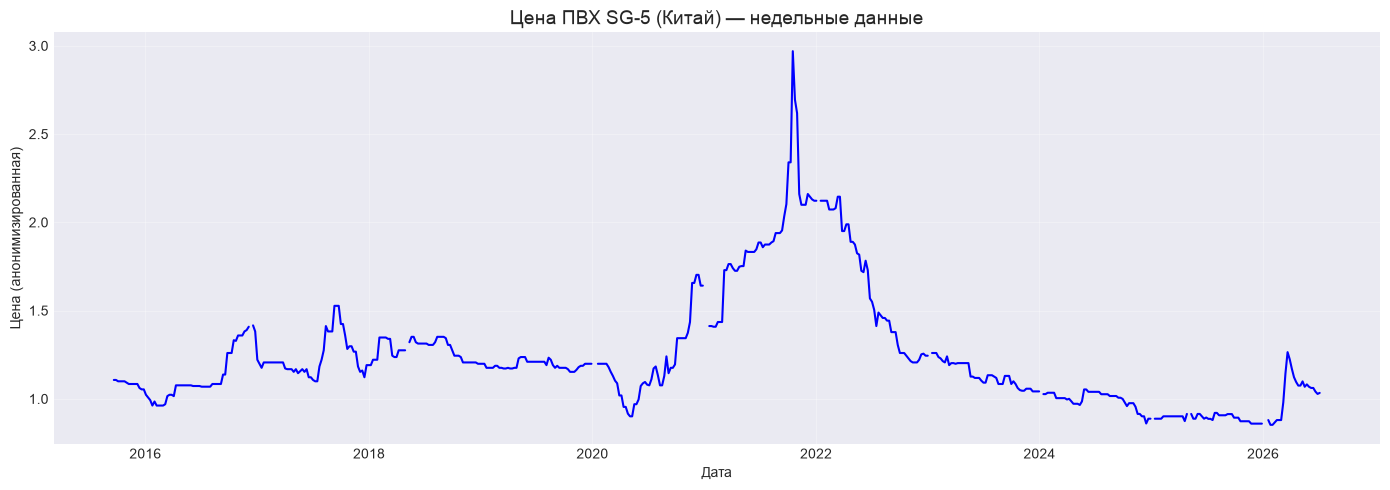

Количество недель: 564
Мин. цена: 0.85, Макс. цена: 2.97


In [13]:
import matplotlib.pyplot as plt

# Агрегируем по неделям (на случай, если есть дубликаты)
target_weekly = df_target.groupby(pd.Grouper(key='report_date', freq='W'))['k'].mean().reset_index()
target_weekly.columns = ['date', 'target_price']

# Рисуем
plt.figure(figsize=(14, 5))
plt.plot(target_weekly['date'], target_weekly['target_price'], linewidth=1.5, color='blue')
plt.title('Цена ПВХ SG-5 (Китай) — недельные данные', fontsize=14)
plt.xlabel('Дата')
plt.ylabel('Цена (анонимизированная)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Количество недель: {len(target_weekly)}")
print(f"Мин. цена: {target_weekly['target_price'].min():.2f}, Макс. цена: {target_weekly['target_price'].max():.2f}")

In [14]:
# Ищем драйверы по nomenclature_ru
drivers = ['Нефть марки Brent', 'Нафта', 'Этилен']
df_drivers = df[df['nomenclature_ru'].str.contains('|'.join(drivers), case=False, na=False)].copy()

for driver in drivers:
    # Берем строки для этого драйвера
    mask = df_drivers['nomenclature_ru'].str.contains(driver, case=False, na=False)
    driver_df = df_drivers[mask]
    
    if len(driver_df) == 0:
        print(f"[!] Для {driver} данных нет")
        continue
    
    # Агрегируем по неделям
    driver_weekly = driver_df.groupby(pd.Grouper(key='report_date', freq='W'))['k'].mean().reset_index()
    driver_weekly.columns = ['date', driver]
    
    # Merge и корреляция
    merged = pd.merge(target_weekly, driver_weekly, on='date', how='inner')
    if len(merged) > 10:
        corr = merged['target_price'].corr(merged[driver])
        print(f"Корреляция ПВХ и {driver}: {corr:.3f} (общих недель: {len(merged)})")
    else:
        print(f"[!] Мало общих точек для {driver}: {len(merged)}")

Корреляция ПВХ и Нефть марки Brent: 0.318 (общих недель: 288)
Корреляция ПВХ и Нафта: 0.347 (общих недель: 564)
Корреляция ПВХ и Этилен: 0.448 (общих недель: 444)


In [15]:
# === Проверка лаговой корреляции ===
import matplotlib.pyplot as plt

# Убедимся, что target_weekly и driver_weekly у нас есть (они были в предыдущих ячейках)
# Если нет — пересоздадим
target_weekly = df_target.groupby(pd.Grouper(key='report_date', freq='W'))['k'].mean().reset_index()
target_weekly.columns = ['date', 'target_price']

drivers = ['Нефть марки Brent', 'Нафта', 'Этилен']
df_drivers = df[df['nomenclature_ru'].str.contains('|'.join(drivers), case=False, na=False)].copy()

for driver in drivers:
    mask = df_drivers['nomenclature_ru'].str.contains(driver, case=False, na=False)
    driver_df = df_drivers[mask]
    if len(driver_df) == 0:
        continue
    
    driver_weekly = driver_df.groupby(pd.Grouper(key='report_date', freq='W'))['k'].mean().reset_index()
    driver_weekly.columns = ['date', driver]
    
    # Merge
    merged = pd.merge(target_weekly, driver_weekly, on='date', how='inner').sort_values('date')
    
    # Считаем корреляцию с лагами 0, 1, 2, 3, 4 недели
    print(f"\n--- {driver} ---")
    for lag in [0, 1, 2, 3, 4]:
        if lag == 0:
            corr = merged['target_price'].corr(merged[driver])
        else:
            corr = merged['target_price'].corr(merged[driver].shift(lag))
        print(f"  Лаг {lag} нед.: корреляция = {corr:.3f}")


--- Нефть марки Brent ---
  Лаг 0 нед.: корреляция = 0.318
  Лаг 1 нед.: корреляция = 0.295
  Лаг 2 нед.: корреляция = 0.265
  Лаг 3 нед.: корреляция = 0.237
  Лаг 4 нед.: корреляция = 0.215

--- Нафта ---
  Лаг 0 нед.: корреляция = 0.347
  Лаг 1 нед.: корреляция = 0.335
  Лаг 2 нед.: корреляция = 0.318
  Лаг 3 нед.: корреляция = 0.300
  Лаг 4 нед.: корреляция = 0.285

--- Этилен ---
  Лаг 0 нед.: корреляция = 0.448
  Лаг 1 нед.: корреляция = 0.432
  Лаг 2 нед.: корреляция = 0.417
  Лаг 3 нед.: корреляция = 0.402
  Лаг 4 нед.: корреляция = 0.387
